In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [2]:
uploaded = files.upload()
file_name = next(iter(uploaded))

Saving kc_house_data.csv to kc_house_data (1).csv


In [3]:
df = pd.read_csv(file_name)

In [4]:
print("First 5 Rows:")
print(df.head())

First 5 Rows:
           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipcode  

In [5]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(21613, 21)


In [6]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


In [7]:
print("\nColumn Names:")
print(df.columns.tolist())



Column Names:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


In [8]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [9]:
numeric_columns = df.select_dtypes(include=np.number).columns


In [10]:
for col in numeric_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())


In [11]:
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())



Missing Values After Cleaning:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [13]:
df.loc[df['bedrooms'] <= 0, 'bedrooms'] = np.nan
df.loc[df['bathrooms'] <= 0, 'bathrooms'] = np.nan

In [14]:
df['bedrooms'] = df['bedrooms'].fillna(
    df['bedrooms'].median()
)

In [15]:
df['bathrooms'] = df['bathrooms'].fillna(
    df['bathrooms'].median()
)


In [16]:
print("\nRoom Counts After Cleaning:")
print(df[['bedrooms', 'bathrooms']].head())


Room Counts After Cleaning:
   bedrooms  bathrooms
0       3.0       1.00
1       3.0       2.25
2       2.0       1.00
3       4.0       3.00
4       3.0       2.00


In [17]:
df['date'] = pd.to_datetime(
    df['date'], format='mixed', errors='coerce'
)


In [18]:
df = df.dropna(subset=['date']).copy()

In [19]:
df['Sale_Year'] = df['date'].dt.year


In [20]:
df['Property_Age'] = (
    df['Sale_Year'] - df['yr_built']
).clip(lower=0)

In [21]:
df['Is_Renovated'] = (
    df['yr_renovated'] > 0
).astype(int)

In [22]:
df['Years_Since_Renovation'] = np.where(
    df['yr_renovated'] > 0,
    (df['Sale_Year'] - df['yr_renovated']).clip(lower=0),
    np.nan
)

In [23]:
print("\nTemporal Attributes:")
print(df[[
    'date', 'Sale_Year', 'yr_built',
    'Property_Age', 'yr_renovated',
    'Is_Renovated', 'Years_Since_Renovation'
]].head())



Temporal Attributes:
        date  Sale_Year  yr_built  Property_Age  yr_renovated  Is_Renovated  \
0 2014-10-13       2014      1955            59             0             0   
1 2014-12-09       2014      1951            63          1991             1   
2 2015-02-25       2015      1933            82             0             0   
3 2014-12-09       2014      1965            49             0             0   
4 2015-02-18       2015      1987            28             0             0   

   Years_Since_Renovation  
0                     NaN  
1                    23.0  
2                     NaN  
3                     NaN  
4                     NaN  


In [24]:
df['Price_Per_Sqft_Living'] = np.where(
    df['sqft_living'] > 0,
    df['price'] / df['sqft_living'],
    np.nan
)

In [25]:
df['Price_Per_Sqft_Lot'] = np.where(
    df['sqft_lot'] > 0,
    df['price'] / df['sqft_lot'],
    np.nan
)

In [26]:
print("\nPrice Per Square Foot:")
print(df[[
    'price', 'sqft_living', 'sqft_lot',
    'Price_Per_Sqft_Living', 'Price_Per_Sqft_Lot'
]].head())


Price Per Square Foot:
      price  sqft_living  sqft_lot  Price_Per_Sqft_Living  Price_Per_Sqft_Lot
0  221900.0         1180      5650             188.050847           39.274336
1  538000.0         2570      7242             209.338521           74.288870
2  180000.0          770     10000             233.766234           18.000000
3  604000.0         1960      5000             308.163265          120.800000
4  510000.0         1680      8080             303.571429           63.118812


In [27]:
property_features = [
    'bedrooms', 'bathrooms', 'sqft_living',
    'sqft_lot', 'grade', 'yr_built'
]

print("\nProperty Feature Summary:")
print(df[property_features].describe())


Property Feature Summary:
           bedrooms     bathrooms   sqft_living      sqft_lot         grade  \
count  21613.000000  21613.000000  21613.000000  2.161300e+04  21613.000000   
mean       3.372646      2.115798   2079.899736  1.510697e+04      7.656873   
std        0.926423      0.768823    918.440897  4.142051e+04      1.175459   
min        1.000000      0.500000    290.000000  5.200000e+02      1.000000   
25%        3.000000      1.750000   1427.000000  5.040000e+03      7.000000   
50%        3.000000      2.250000   1910.000000  7.618000e+03      7.000000   
75%        4.000000      2.500000   2550.000000  1.068800e+04      8.000000   
max       33.000000      8.000000  13540.000000  1.651359e+06     13.000000   

           yr_built  
count  21613.000000  
mean    1971.005136  
std       29.373411  
min     1900.000000  
25%     1951.000000  
50%     1975.000000  
75%     1997.000000  
max     2015.000000  


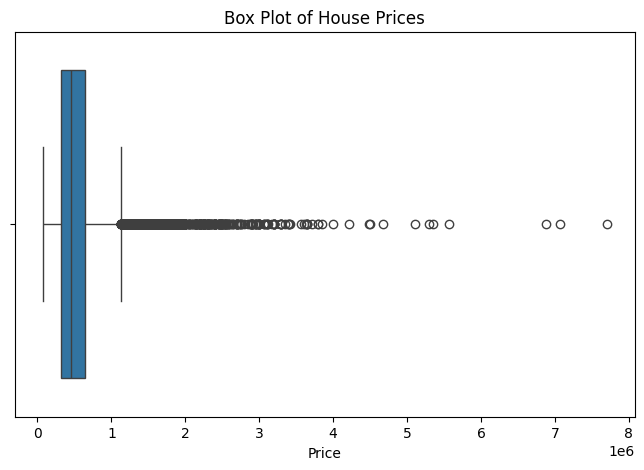

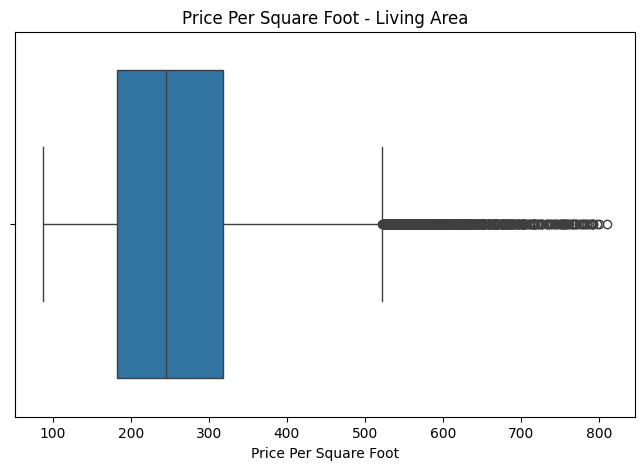

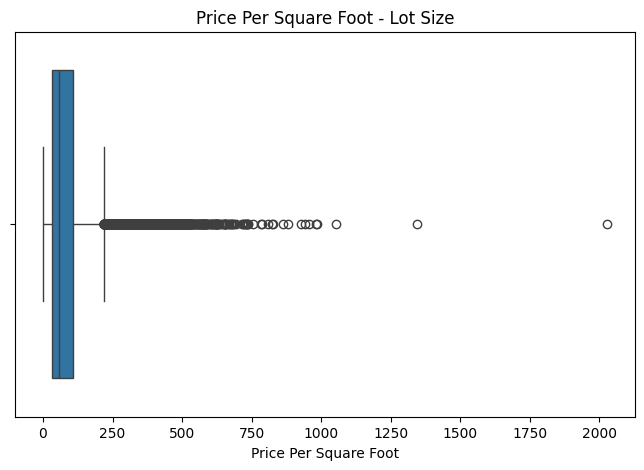

In [28]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['price'])
plt.title('Box Plot of House Prices')
plt.xlabel('Price')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Price_Per_Sqft_Living'])
plt.title('Price Per Square Foot - Living Area')
plt.xlabel('Price Per Square Foot')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Price_Per_Sqft_Lot'])
plt.title('Price Per Square Foot - Lot Size')
plt.xlabel('Price Per Square Foot')
plt.show()

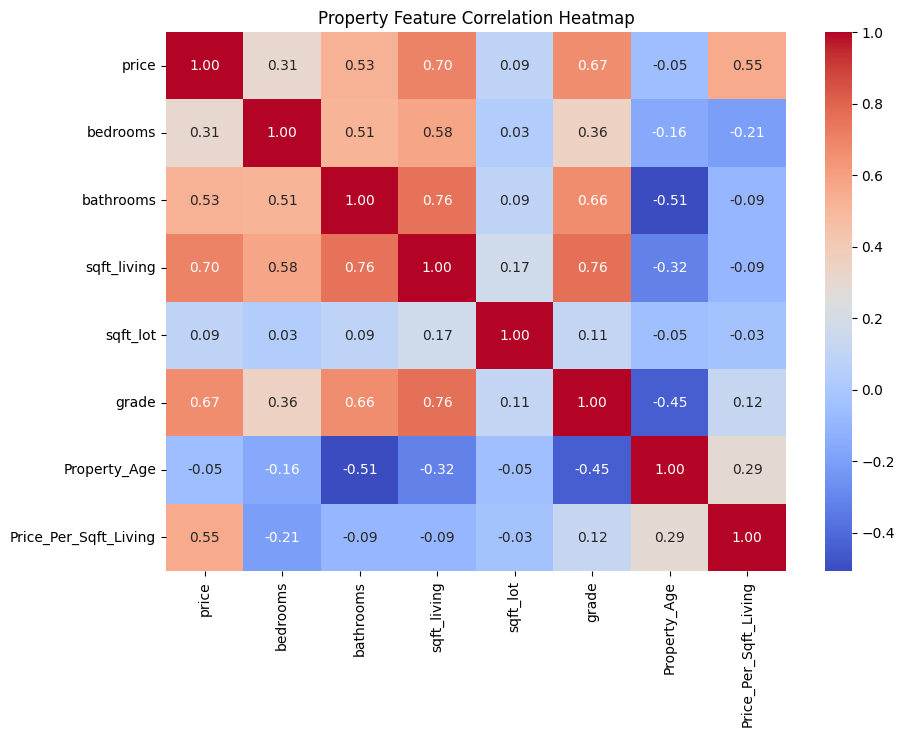

In [29]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[[
        'price', 'bedrooms', 'bathrooms',
        'sqft_living', 'sqft_lot', 'grade',
        'Property_Age', 'Price_Per_Sqft_Living'
    ]].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Property Feature Correlation Heatmap')
plt.show()

In [30]:
output_file = 'cleaned_house_data.csv'
df.to_csv(output_file, index=False)

print("\nCleaned Dataset Shape:", df.shape)
print("\nCleaned Dataset Preview:")
print(df.head())

files.download(output_file)

print("\nData Cleaning and Feature Engineering Completed!")


Cleaned Dataset Shape: (21613, 27)

Cleaned Dataset Preview:
           id       date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520 2014-10-13  221900.0       3.0       1.00         1180   
1  6414100192 2014-12-09  538000.0       3.0       2.25         2570   
2  5631500400 2015-02-25  180000.0       2.0       1.00          770   
3  2487200875 2014-12-09  604000.0       4.0       3.00         1960   
4  1954400510 2015-02-18  510000.0       3.0       2.00         1680   

   sqft_lot  floors  waterfront  view  ...      lat     long  sqft_living15  \
0      5650     1.0           0     0  ...  47.5112 -122.257           1340   
1      7242     2.0           0     0  ...  47.7210 -122.319           1690   
2     10000     1.0           0     0  ...  47.7379 -122.233           2720   
3      5000     1.0           0     0  ...  47.5208 -122.393           1360   
4      8080     1.0           0     0  ...  47.6168 -122.045           1800   

   sqft_lot15  Sale_Year  Prop

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Data Cleaning and Feature Engineering Completed!
